# Jobs 51114734 / 51151957 — the width ladder, and what happened when width was handed back

Two things finished together, and they answer different halves of one question.

**Stage C (`51114734`, 15/15)** completed the complete model's width ladder at
`d_model` 256 / 192 / 128 / 64. **Stage D (`51151957`)** ran the test no earlier
cell in this grid had run: every ablated rung measured before it sat at AT MOST
the hub's depth and at most its width, so no ablated model had ever been handed
*more* of a resource than the model it is scored against. D2 is attention-only —
no MLP anywhere — at `d_model` 384, 1.5× the hub's residual stream.

Everything below is scored by `scripts/capacity_back.py`, which was written and
committed **before the deciding cells landed** (`e5d1e5d`, `925f5cd`, `3f139de`)
and is pinned to the sbatch headers by 15 tests. This notebook runs it; it does
not restate its conclusions in its own words.

**No improvement is claimed and none was sought.** The brief since 2026-11-04 is
the smallest or most analytically tractable architecture that still learns direct
deduction, not a stronger solver. Section 5 gives the comparison against the
previous best on the same eval explicitly.

In [1]:
import json, os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

REPO = "/home/users/hshunt/spin_gnn"
BOOT = 2000          # the programme's scoring default; CIs here match the scorers'
SEEDS = (0, 1, 2)    # every rung here is 3 seeds unless the table says otherwise

from scripts.minarch_analysis import SCAN_DEFAULT, SCAN_L6, SCAN_C, SCAN_D
from scripts.capacity_back import BARRIER_LO, BARRIER_HI, FREE, D1, D2
from scripts.stagec_score import HUB, PLATEAU, S_RHO50, S_MEAN, escapes, rung, summarize
from notebooks.make_widtharm_deck import FULL_WIDTHS, NOMLP_WIDTHS, NO_MLP_D256, collect

# Stage E (51171824) is deliberately NOT read here. Its rungs carry entirely
# default hyperparameters, so they key as plain (8,4,'no_mlp')/(12,4,'no_mlp')
# and would pool into the s* that every verdict below was already scored
# against. A new rung must never move the bar an existing verdict was measured
# with; stage E gets its own notebook when it lands.
DIRS = [SCAN_DEFAULT, SCAN_L6, SCAN_C, SCAN_D]

COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO,
                        capture_output=True, text=True).stdout.strip()
print("git commit        ", COMMIT)
print("branch            ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                           cwd=REPO, capture_output=True,
                                           text=True).stdout.strip())
print("bootstrap draws   ", BOOT)
print("frozen yardstick  ", f"s* = {S_RHO50} in rho_50, {S_MEAN} in mean_solve")
print("plateau           ", f"train NLL {PLATEAU} (finding 44)")
print("free/not-free     ", f"rho_50 <= {FREE:.3f}; barrier band [{BARRIER_LO:.2f}, "
                            f"{BARRIER_HI:.2f}]")
for d in DIRS:
    print("scan dir          ", d)

git commit         208d2a5
branch             sudoku-dd
bootstrap draws    2000
frozen yardstick   s* = 0.1484 in rho_50, 0.2918 in mean_solve
plateau            train NLL 1.64 (finding 44)
free/not-free      rho_50 <= 0.740; barrier band [0.72, 0.80]
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_2026-11-04
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_L6_2026-11-04
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_C_2026-11-04
scan dir           /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_D_2026-11-04


## 1. Provenance: the config every rung was actually run with

Read off each cell's `config.json` rather than from the sbatch headers, because
stage D's header turned out to have mis-estimated its own parameter count by 4%.
The two ladders differ from the hub in exactly one field apiece — `d_model` for
the complete ladder, `d_model` and `arch_mode` for the attention-only one.

In [2]:
cells = collect(DIRS, BOOT)
hub = summarize(rung(cells, HUB))
d1, d2 = summarize(rung(cells, D1)), summarize(rung(cells, D2))
print(f"{len(cells)} cells on disk | D1 {d1['n']}/3 seeds, D2 {d2['n']}/3 seeds\n")

FIELDS = ("num_layers", "d_model", "dim_feedforward", "nhead", "arch_mode", "warmup_epochs",
          "lr", "batch_size", "n_train_instances", "epochs", "shuffle_adj", "fall",
          "n_nodes", "degree", "n_colors", "seed")
print(f"{'rung':<20}" + "".join(f"{f.replace('_', ' ')[:9]:>11}" for f in FIELDS[:6]))
print("-" * 86)
for (d, key), tag in ([(w, "full") for w in FULL_WIDTHS] +
                      [(w, "no_mlp") for w in NOMLP_WIDTHS]):
    ms = rung(cells, key)
    if not ms:
        continue
    cfg = json.load(open(os.path.join(ms[0]["path"], "config.json")))
    print(f"{tag + ' d' + str(d):<20}" + "".join(f"{str(cfg.get(f)):>11}" for f in FIELDS[:6]))
print()
cfg = json.load(open(os.path.join(rung(cells, HUB)[0]["path"], "config.json")))
print("held constant across every rung:",
      "  ".join(f"{f}={cfg.get(f)}" for f in FIELDS[8:-1]))
print("seeds per rung:", SEEDS, " (seed is the only thing that varies within a rung)")

72 cells on disk | D1 3/3 seeds, D2 3/3 seeds

rung                  num layer    d model  dim feedf      nhead  arch mode  warmup ep
--------------------------------------------------------------------------------------
full d256                     6        256       1024          4       full          0
full d192                     6        192       1024          4       full          0
full d128                     6        128       1024          4       full          0
full d64                      6         64       1024          4       full          0
no_mlp d384                   6        384       1024          4     no_mlp          0
no_mlp d256                   6        256       1024          4     no_mlp          0
no_mlp d128                   6        128       1024          4     no_mlp          0

held constant across every rung: n_train_instances=240000  epochs=50  shuffle_adj=True  fall=True  n_nodes=48  degree=5  n_colors=4
seeds per rung: (0, 1, 2)  (seed is t

## 2. The metrics table

`rho_50` is the realized hint density at which the solve rate crosses 0.5 on a
14-point × 400-instance leak-free grid — **lower is better** — and it CENSORS
once no bin clears 0.5. `mean_solve` is the unweighted mean over the 14 bins and
never censors, which is why the censored rungs are still readable here.

The `esc` column is the one that decides how a row may be *worded*: it counts
seeds that finished below the 1.64 train-NLL plateau. A rung at 0/3 did not train
in 375k steps, and is never evidence about width in either direction.

In [3]:
LADDERS = ([("full", d, k) for d, k in sorted(FULL_WIDTHS, reverse=True)]
           + [("no_mlp", d, k) for d, k in sorted(NOMLP_WIDTHS, reverse=True)])

print(f"{'rung':<16}{'rho_50':>10}{'mean_solve':>12}{'spread':>9}"
      f"{'trainable':>12}{'esc':>6}   train NLL per seed")
print("-" * 104)
for tag, d, key in LADDERS:
    ms = rung(cells, key)
    if not ms:
        print(f"{tag + ' d' + str(d):<16}   (nothing on disk yet)")
        continue
    s, (n_esc, nll) = summarize(ms), escapes(ms)
    rho = f"{s['rho50']:.3f}" if s["rho50_readable"] else "CENSORED"
    spr = f"{s['spread_mean']:.4f}" if s["spread_mean"] == s["spread_mean"] else "-"
    print(f"{tag + ' d' + str(d):<16}{rho:>10}{s['mean_solve']:>12.4f}{spr:>9}"
          f"{s['trainable']:>12,}{n_esc:>4}/{s['n']}   "
          + "/".join(f"{v:.3f}" for v in nll))
print()
print(f"the hub (full d256) is the paired control for every row: rho_50 {hub['rho50']:.3f}, "
      f"mean_solve {hub['mean_solve']:.4f}, {hub['trainable']:,} trainable")

rung                rho_50  mean_solve   spread   trainable   esc   train NLL per seed
--------------------------------------------------------------------------------------------------------
full d256            0.592      0.5389   0.0141   4,899,898   3/3   1.524/1.528/1.530
full d192            0.752      0.3266   0.0268   3,381,562   3/3   1.565/1.555/1.555
full d128         CENSORED      0.0273   0.0036   2,059,834   2/3   1.623/1.649/1.621
full d64          CENSORED      0.0013   0.0005     934,714   0/3   1.712/1.715/1.724
no_mlp d384          0.760      0.3155   0.0075   3,799,354   3/3   1.619/1.616/1.612
no_mlp d256          0.763      0.3039   0.2671   1,746,490   2/3   1.631/1.688/1.597
no_mlp d128       CENSORED      0.0291   0.2075     480,058   0/3   1.725/1.738/1.706

the hub (full d256) is the paired control for every row: rho_50 0.592, mean_solve 0.5389, 4,899,898 trainable


## 3. The pre-registered scorer, run as it was committed

`scripts/capacity_back.py` transcribes every threshold from the stage D and
stage E sbatch headers, checks trainability FIRST, and refuses to score a rung
with fewer than three seeds. Its branch order is itself registered and pinned by
`tests/test_capacity_back.py`.

It also reports, rather than quietly resolves, a contradiction inside the
registration: the stage E header's tie-break sends any median in
[0.72, 0.740] to the barrier reading, while its falsifier kills that reading for
any median below 0.740 on ≥2 of 3 crossing seeds. The scorer follows the
tie-break — written for exactly that overlap, and the conservative choice, since
the capacity reading is the claim that needs evidence — and prints BOTH readings
whenever a median lands in the disputed interval.

In [4]:
out = subprocess.run([sys.executable, "-m", "scripts.capacity_back", "--boot", str(BOOT)],
                     cwd=REPO, capture_output=True, text=True)
print(out.stdout)
if out.returncode:
    print("STDERR:", out.stderr[-2000:])

STAGES D AND E: giving an ablated model capacity back, on two axes
  74 cells read from 5 directories (SCAN_E added by hand; it is out of SCAN_DIRS on purpose)
  frozen bar s* = 0.1484 rho_50 / 0.2918 mean_solve, NOT recomputed
  hub (L=6 d256 ff1024 h4 full): rho_50 0.592  mean_solve 0.5389  4,899,898 trainable
  (A) BARRIER window [0.72, 0.80];  falsified only by a median below 0.72 on >=2 of 3 crossing seeds

PAIRED REFERENCE RUNGS, all at this exact budget and grid:
  full L=8 (E1's depth partner)      rho_50    0.471   mean_solve 0.7111   6,479,418 trainable
  full L=12 (E2's depth partner)     rho_50    0.385   mean_solve 0.8163   9,638,458 trainable
  no_mlp L=6 d256 (the single knob)  rho_50    0.763   mean_solve 0.3039   1,746,490 trainable

=== D1 -- bisect the width cliff, full d192 ===
  3/3 seeds on disk, 3/3 crossed 0.5
  rho_50 median 0.752   (hub 0.592)
  mean_solve median 0.3266 [spread 0.0268]   (hub 0.5389)
  trainable 3,381,562   (hub 4,899,898)
  plateau escapes 3/

## 4. The two ladders, and where stage D landed

The same figures as pages 4 and 5 of the slide deck, drawn by the deck's own code
so the two cannot drift apart.

A hollow marker means the rung never escaped the plateau. Censored rungs cannot
be placed on a `rho_50` axis and are omitted from the second figure; all of them
sit BELOW the band, so omitting them understates the pile-up rather than
flattering it.

attention-only at d256: 1,746,490 trainable, mean_solve 0.3039, rho_50 0.763
complete model at d128: 2,059,834 trainable, mean_solve 0.0273, rho_50 CENSORED (no bin crosses)
the smaller model is the one that solves, so capacity alone does not order these rows


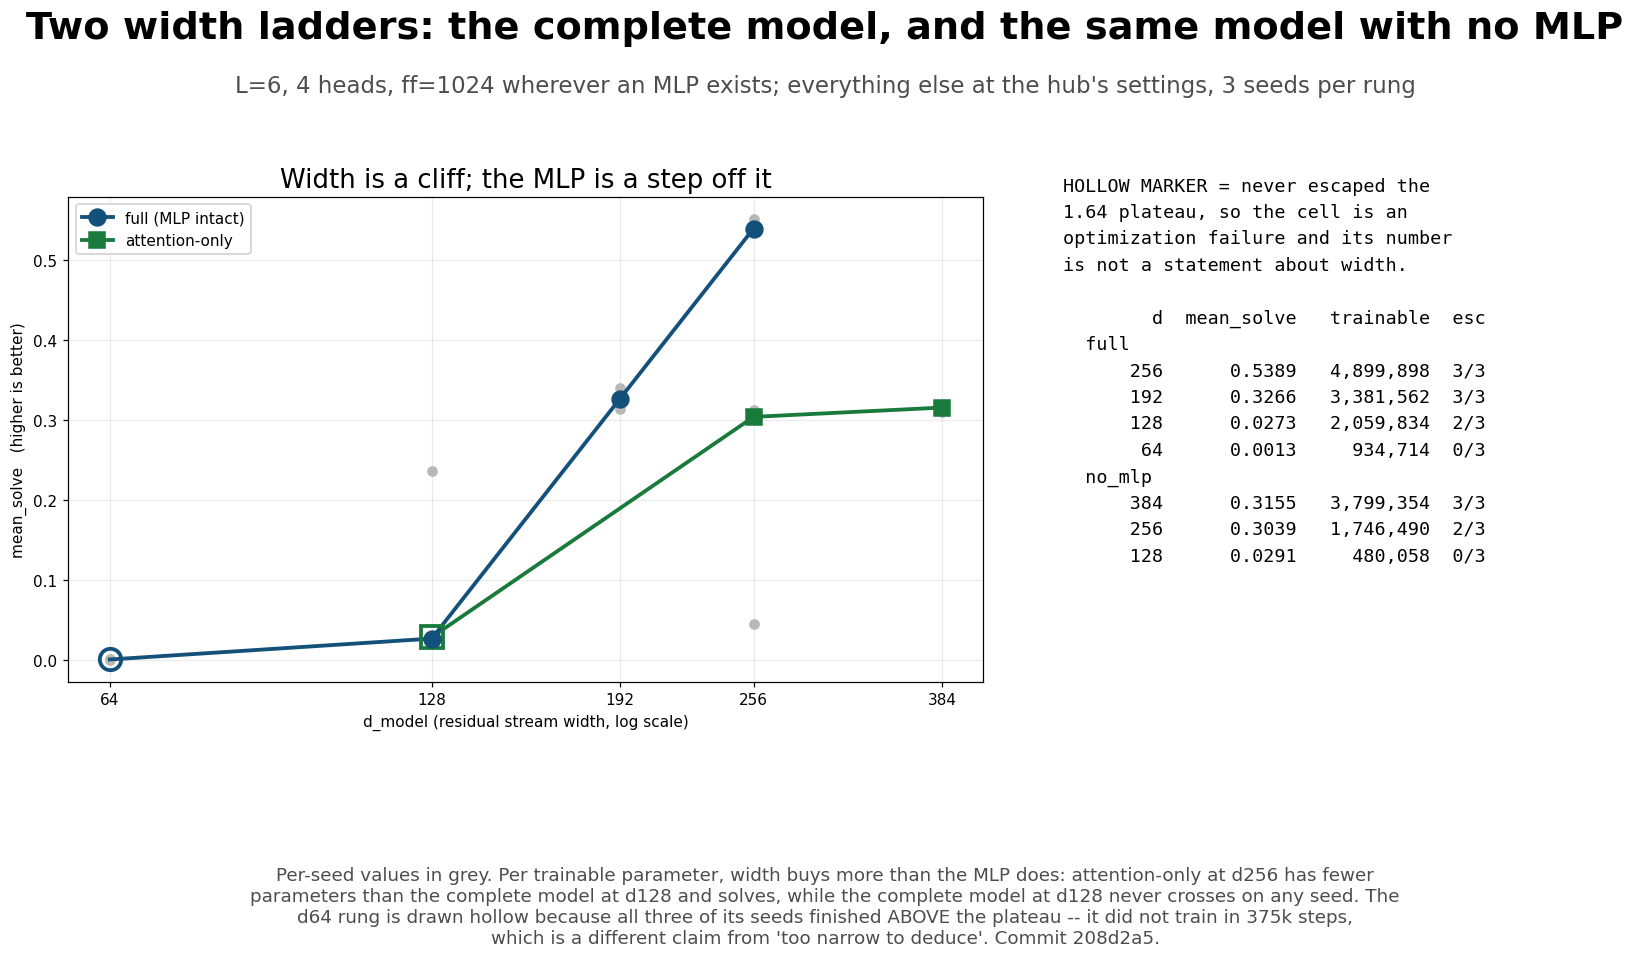

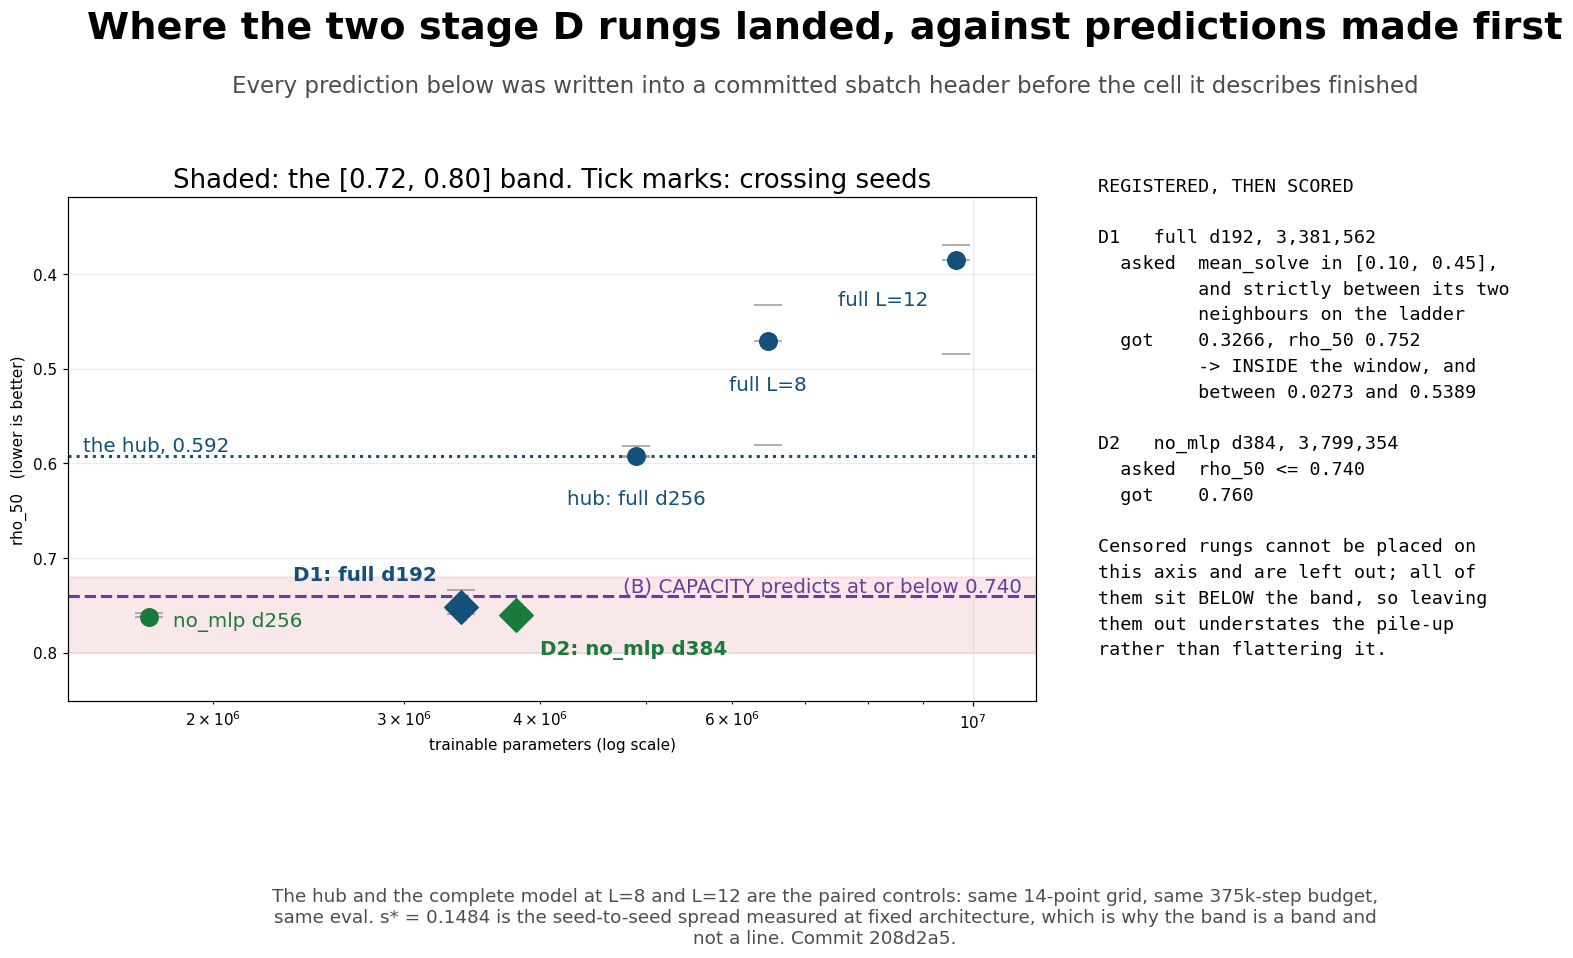

In [5]:
from notebooks.make_widtharm_deck import page_ladders, page_band


class Keep:
    """A PdfAndPng stand-in that keeps the figure open for the notebook."""

    def savefig(self, fig):
        pass


page_ladders(Keep(), cells, COMMIT)
page_band(Keep(), cells, d1, d2, hub, COMMIT)

nomlp = summarize(rung(cells, NO_MLP_D256))
full128 = summarize(rung(cells, (6, 4, "full", 128, 1024, 0)))
print(f"attention-only at d256: {nomlp['trainable']:,} trainable, mean_solve "
      f"{nomlp['mean_solve']:.4f}, rho_50 {nomlp['rho50']:.3f}")
print(f"complete model at d128: {full128['trainable']:,} trainable, mean_solve "
      f"{full128['mean_solve']:.4f}, rho_50 "
      + (f"{full128['rho50']:.3f}" if full128["rho50_readable"] else "CENSORED (no bin crosses)"))
print("the smaller model is the one that solves, so capacity alone does not order these rows")

## 5. Comparison against the previous best on the same eval

Required by the brief and stated plainly: **nothing here is an improvement.** The
eval is unchanged — the same 14-point × 400-instance leak-free grid, the same
375k-step budget, `--shuffle-adj --fall` throughout — so these numbers are
directly comparable to every earlier rung, and the complete model at L=12 remains
the best solver this programme has produced.

What changed is the *question*. The figure of merit now is the smallest rung that
still solves, which is the bottom block below.

In [6]:
from scripts.rung_collapse import BAND_HI

# "Still solves" is the band criterion the rest of the programme uses: a
# complete 3-seed rung whose median rho_50 is readable and no worse than the
# band's upper edge. Picking the smallest readable rung instead would promote
# a cell that crosses only at the very top of the grid.
solving = []
for key in set(k[:-1] for k in cells):
    s = summarize(rung(cells, key))
    if s["n"] >= 3 and s["rho50_readable"] and s["rho50"] <= BAND_HI:
        solving.append((key, s))
best = sorted(solving, key=lambda kv: kv[1]["rho50"])
smallest = min(solving, key=lambda kv: kv[1]["trainable"])


def name(key):
    if len(key) == 3:
        return f"L={key[0]} {key[2]}"
    L, h, arch, d, ff, wu = key
    bits = [f"L={L}", arch] + ([f"h{h}"] if h != 4 else []) + ([f"d{d}"] if d != 256 else [])
    return " ".join(bits + ([f"ff{ff}"] if ff != 1024 else []) + ([f"wu{wu}"] if wu else []))


print("BEST ON THIS EVAL -- same grid, same budget, same eval")
print(f"  {'rung':<18}{'rho_50':>9}{'mean_solve':>12}{'trainable':>12}")
print("  " + "-" * 51)
for i, (key, s) in enumerate(best[:4]):
    tag = "   <- PREVIOUS BEST" if i == 0 else (
        "   <- the hub, paired control" if key == HUB else "")
    print(f"  {name(key):<18}{s['rho50']:>9.3f}{s['mean_solve']:>12.4f}"
          f"{s['trainable']:>12,}{tag}")
print()
print("SMALLEST RUNG IN THIS GRID THAT STILL SOLVES -- the figure of merit now")
print(f"  {name(smallest[0]):<18}{smallest[1]['rho50']:>9.3f}"
      f"{smallest[1]['mean_solve']:>12.4f}{smallest[1]['trainable']:>12,}")
print()
s = smallest[1]
print(f"  vs the hub:  {hub['trainable'] / s['trainable']:.2f}x fewer trainable parameters, "
      f"rho_50 worse by {s['rho50'] - hub['rho50']:+.3f} "
      f"({(s['rho50'] - hub['rho50']) / S_RHO50:.1f} s*)")
print(f"  vs the best: rho_50 worse by {s['rho50'] - best[0][1]['rho50']:+.3f} at "
      f"{best[0][1]['trainable'] / s['trainable']:.1f}x fewer parameters")
print()
nm = summarize(rung(cells, NO_MLP_D256))
print(f"  D2 (no_mlp d384) is NOT the smallest rung: {d2['trainable']:,} trainable, "
      f"{d2['trainable'] / nm['trainable']:.1f}x the")
print(f"  attention-only rung at d256. rho_50 "
      + (f"{d2['rho50']:.3f}" if d2["rho50_readable"] else "CENSORED")
      + f" against that rung's {nm['rho50']:.3f} -- section 3 has")
print("  the scorer's call on it, which is the only place this notebook judges that pair.")

BEST ON THIS EVAL -- same grid, same budget, same eval
  rung                 rho_50  mean_solve   trainable
  ---------------------------------------------------
  L=12 full             0.385      0.8163   9,638,458   <- PREVIOUS BEST
  L=8 full              0.471      0.7111   6,479,418
  L=6 full              0.592      0.5389   4,899,898   <- the hub, paired control
  L=6 full ff256        0.740      0.3320   2,535,994

SMALLEST RUNG IN THIS GRID THAT STILL SOLVES -- the figure of merit now
  L=6 no_mlp            0.763      0.3039   1,746,490

  vs the hub:  2.81x fewer trainable parameters, rho_50 worse by +0.171 (1.2 s*)
  vs the best: rho_50 worse by +0.378 at 5.5x fewer parameters

  D2 (no_mlp d384) is NOT the smallest rung: 3,799,354 trainable, 2.2x the
  attention-only rung at d256. rho_50 0.760 against that rung's 0.763 -- section 3 has
  the scorer's call on it, which is the only place this notebook judges that pair.


## 6. Stage C's own registered rows, now complete

`scripts/stagec_score.py` scores stage C's five registered predictions against
the frozen `s*` and the paired control, both fixed before stage C ran. P5 is new
here: the rungcollapse notebook ran at 13 of 15 cells, this one at 15.

**P5 is an optimization failure, not a capacity one.** `full` d64 is censored on
all three seeds at `mean_solve` 0.0013, but it escaped the plateau 0 of 3 times
(train NLL 1.712 / 1.715 / 1.724, every seed ABOVE 1.64), so the registered
wording is *"did not train in 375k steps"*, not *"too narrow to deduce"* — the
distinction P2 collapsed. P1's d128 is the opposite and is the clean negative
result: 2 of 3 seeds got below the plateau and it still never crosses.

In [7]:
out = subprocess.run([sys.executable, "-m", "scripts.stagec_score", "--boot", str(BOOT)],
                     cwd=REPO, capture_output=True, text=True)
print(out.stdout)
if out.returncode:
    print("STDERR:", out.stderr[-2000:])

STAGE C (51114734), scored against its own sbatch header
  bar in force at submission: s* = 0.1484 rho_50, 0.2918 mean_solve
  paired control  L=6  h=4 full  rho_50 0.592  mean_solve 0.5389  trainable 4,899,898
  a removal is 'free' iff rho_50 stays at or below 0.740

=== P1 -- width 256->128 ===
  3/3 seeds on disk, 0/3 crossed 0.5
  rho_50 median CENSORED   (hub 0.592)
  mean_solve median 0.0273 [spread 0.0036]   (hub 0.5389)
  trainable 2,059,834   (hub 4,899,898)
  plateau escapes 2/3   train NLL 1.623/1.649/1.621
  >>> FALSIFIED by its own registered falsifier, which reads 'gap > s*, or any
      seed censored while all three hub seeds solved'. 3 of 3 seeds never
      crossed 0.5 at any of the 14 hint densities, and all three hub seeds did.
      Halving the residual stream is NOT free: the width is itself load-bearing
      at N=48 and the minimal architecture is bounded below by it.
      AND IT IS NOT A TRAINABILITY ARTEFACT -- 2 of 3 seeds got below finding
      44's plateau

## 7. What this does not settle, and what is still running

Stage D answers the width half. **`51171824` stage E** is the depth half:
attention-only at L=8 and L=12, three seeds each, both chosen because the
complete model is already measured at those depths, so every rung has a paired
partner at identical depth. Its registered falsifier of the barrier reading is
either rung with a median below the tie-break floor on at least 2 of 3 crossing
seeds — no partial credit, and no "but the other rung held".

**The named way stage E produces nothing is trainability, not capacity.**
Attention-only escapes the 1.64 plateau 2/3 at L=6 and 0/3 at L=4, so a *deeper*
attention-only stack failing to escape is the expected failure mode and will be
written "did not train in 375k steps". The budget is deliberately not raised to
rescue it: a rung trained on a different budget cannot be read against the ladder
it is compared to; a longer-budget rerun is a follow-up cell, not a fix.

After stage E, whichever rung survives gets a 3-seed replicate at **N=96**, to
show the minimum is not an N=48 artifact. Which rung that is depends on the
verdict, which is why it has not been submitted yet.